## Co-variation
pymaftools: https://github.com/xu62u4u6/pymaftools/blob/main/pymaftools/core/Clustering.py

為何部分相似，但也不是很像，但套到其他 cancer type 的 performance 跟用自己建立的 cancer-specific model 結果差不多?

In [1]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/utils/")
cancer_type = "PAAD"
random_seed = 42

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Load features & tables 
top_features_CHOL = np.load(f"/home/data/data_YM313112004/TLS_model/results/CHOL/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_PAAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_STAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/STAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
pooled_sig = np.load(f"/home/data/data_YM313112004/TLS_model/results/all/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)

chol_rna  = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite")
paad_rna  = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite")
stad_rna  = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite")
chol_meth = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite")
paad_meth = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite")
stad_meth = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite")
all_rna  = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/all/table/rna_table.sqlite")
all_meth = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/all/table/meth_table.sqlite")

chol_rna_df  = chol_rna.T   # (172 samples × 19026 genes)
paad_rna_df  = paad_rna.T    
stad_rna_df  = stad_rna.T
chol_meth_df = chol_meth.T
paad_meth_df = paad_meth.T
stad_meth_df = stad_meth.T
all_rna_df  = all_rna.T
all_meth_df = all_meth.T

print("CHOL RNA shape :", chol_rna_df.shape)
print("PAAD RNA shape :", paad_rna_df.shape)
print("STAD RNA shape :", stad_rna_df.shape)
print("CHOL Meth shape:", chol_meth_df.shape)
print("PAAD Meth shape:", paad_meth_df.shape)
print("STAD Meth shape:", stad_meth_df.shape)
print("All RNA shape :", all_rna_df.shape)
print("All Meth shape :", all_meth_df.shape)

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/all/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/all/table/meth_table.sqlite
CHOL RNA shape : (34, 19026)
PAAD RNA shape : (172, 19026)
STAD RNA shape : (355, 19026)
CHOL Meth shape: (34, 146132)
PAAD Meth shape: (172, 154359)
STAD Meth shape: (355, 156220)
All RNA shape : (561, 190

In [3]:
# 取 feature expression（保留 RNA_ / Meth_ 前綴）
def extract_features(rna_df, meth_df, top_features):
    selected = {}
    missing = []
    top_features = pd.Series(top_features).astype(str)

    for feat in top_features:
        if feat.startswith("RNA_"):
            key = feat.replace("RNA_", "", 1)
            src = rna_df
        elif feat.startswith("Meth_"):
            key = feat.replace("Meth_", "", 1)
            src = meth_df
        else:
            missing.append(feat)
            continue

        val = None
        if key in src.columns:
            val = src[key]
        elif key in src.index:
            val = src.loc[key]

        if val is None:
            missing.append(feat)
            continue

        if isinstance(val, pd.Series):
            ser = pd.to_numeric(val, errors="coerce")
        elif isinstance(val, pd.DataFrame):
            if val.shape[1] == 1:
                ser = pd.to_numeric(val.iloc[:, 0], errors="coerce")
            else:
                ser = val.apply(pd.to_numeric, errors="coerce").mean(axis=1)
        else:
            arr = np.asarray(val)
            if arr.ndim == 0:
                arr = np.array([arr.item()])
            elif arr.ndim > 1:
                arr = arr.reshape(arr.shape[0], -1)
                arr = np.nanmean(arr, axis=1)
            ser = pd.Series(pd.to_numeric(arr, errors="coerce"))

        selected[feat] = ser.reset_index(drop=True)

    if missing:
        print(f"WARNING missing features: {missing}")

    if not selected:
        return pd.DataFrame()

    max_len = max(len(s) for s in selected.values())
    selected = {k: v.reindex(range(max_len)) for k, v in selected.items()}
    return pd.concat(selected, axis=1)

chol_expr = extract_features(chol_rna_df, chol_meth_df, top_features_CHOL)
paad_expr = extract_features(paad_rna_df, paad_meth_df, top_features_PAAD)
stad_expr = extract_features(stad_rna_df, stad_meth_df, top_features_STAD)
print("CHOL expr shape:", chol_expr.shape)  
print("PAAD expr shape:", paad_expr.shape)
print("STAD expr shape:", stad_expr.shape)

CHOL expr shape: (34, 38)
PAAD expr shape: (172, 24)
STAD expr shape: (355, 16)


### Co-variation patterns of TLS signatures (Clustering)

In [4]:
from model_utils import concat_omics
chol_concat = concat_omics([chol_rna, chol_meth], keys=["RNA", "Meth"], axis=0)
paad_concat = concat_omics([paad_rna, paad_meth], keys=["RNA", "Meth"], axis=0)
stad_concat = concat_omics([stad_rna, stad_meth], keys=["RNA", "Meth"], axis=0)
#all_concat = concat_omics([all_rna, all_meth], keys=["RNA", "Meth"], axis=0)

#top_features_all = list((set(top_features_CHOL) | set(top_features_PAAD) | set(top_features_STAD)))
top_features_all = list((set(top_features_CHOL) | set(top_features_PAAD) | set(top_features_STAD) | set(pooled_sig)) - set(['Meth_cg16829924', 'Meth_cg18634760', 'Meth_cg24083364']))

# 使用 cancer-specific features 的 union (排除 missing feature)
chol_table = chol_concat.subset(features=top_features_all)
paad_table = paad_concat.subset(features=top_features_all)
stad_table = stad_concat.subset(features=top_features_all)
#all_table = all_concat.subset(features=top_features_all)

In [5]:
from sklearn.preprocessing import StandardScaler

def zscore_cohort(table):
    scaler = StandardScaler()
    table_scaled = pd.DataFrame(scaler.fit_transform(table.T).T, index=table.index, columns=table.columns)
    table_scaled = PivotTable(table_scaled)
    table_scaled.feature_metadata = table.feature_metadata
    table_scaled.sample_metadata = table.sample_metadata
    return table_scaled

# 對每個 cohort 分別進行 z-score normalization
paad_table_scaled = zscore_cohort(paad_table)
chol_table_scaled = zscore_cohort(chol_table)
stad_table_scaled = zscore_cohort(stad_table)

In [6]:
all_table_scaled = PivotTable.merge([paad_table_scaled, chol_table_scaled, stad_table_scaled], join="outer")
all_table_scaled

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-HU-A4GD-01A,TCGA-VQ-A91A-01A,TCGA-VQ-A94P-01A,TCGA-HU-8608-01A,TCGA-BR-A4J1-01A,TCGA-D7-A6EY-01A,TCGA-VQ-A928-01A,TCGA-FP-7916-01A,TCGA-D7-8570-01A,TCGA-F1-6177-01A
Meth_cg02654291,-1.061161,-0.606623,-0.690625,-0.236207,-0.128268,-0.555688,-0.965312,-0.941980,0.249825,1.170059,...,-1.109582,0.034334,0.385226,0.838569,-1.920149,1.030163,-0.577198,1.183836,0.761169,-1.439943
RNA_CXCL13,-1.188377,-1.046651,-0.329506,0.789415,-0.689042,-1.314064,-0.104581,-1.284257,0.934976,0.869375,...,-1.116008,-1.370255,-0.023713,1.234343,-2.068829,1.896139,-0.635688,0.495812,0.999903,-0.869990
Meth_cg14584255,2.925165,0.143804,0.083868,-1.095956,0.073405,-1.346967,0.446125,-1.957807,-0.319724,0.759248,...,-1.425488,-0.904607,-0.604781,1.935184,-1.556199,0.243109,-0.617430,0.571920,1.323371,-1.384399
Meth_cg07824172,1.419220,0.757044,0.664995,0.806231,-0.710055,1.734881,0.236660,0.385092,-0.324628,-1.057259,...,0.657793,1.045834,-1.013563,0.383606,-1.581050,0.705930,0.108317,0.236072,0.044955,1.491184
RNA_CD79A,-0.832557,0.445222,-1.321861,0.654799,-0.703225,-1.502289,0.033266,-1.449267,0.825741,1.032379,...,-1.162208,-0.475757,-0.192187,0.829699,-1.530649,1.355091,-0.757804,1.530983,0.971285,-1.910353
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RNA_NIBAN3,-0.627365,-0.547398,-0.555689,1.075206,-0.700761,-0.513115,0.107368,-0.721499,0.292254,0.719486,...,1.621986,-0.579048,-0.293792,-0.306825,-0.757754,1.764565,-0.491678,0.471553,-0.299495,-0.656147
RNA_TGFB2,-0.532327,-0.884174,0.807218,0.490696,-0.230371,-1.000022,0.544752,1.717801,0.164630,-1.478621,...,-1.320139,1.026224,2.060892,0.541193,0.103782,0.635488,0.223921,0.240338,-0.311641,-0.475677
RNA_CD19,-0.778950,-0.677129,-0.709289,0.947408,-0.771194,-0.940279,-0.079449,-0.776287,0.906035,0.951610,...,0.661300,-0.542070,-0.240693,1.051332,-0.168231,1.885166,-0.786125,0.980710,0.586161,-1.103661
RNA_FCRL1,-0.671232,-0.689398,-0.670785,1.092605,-0.689398,-0.651700,-0.118173,-0.630120,0.355500,-0.232713,...,-0.001142,-0.585786,0.050314,0.263526,-0.729215,1.764259,-0.428296,0.367195,-0.219921,-0.700894


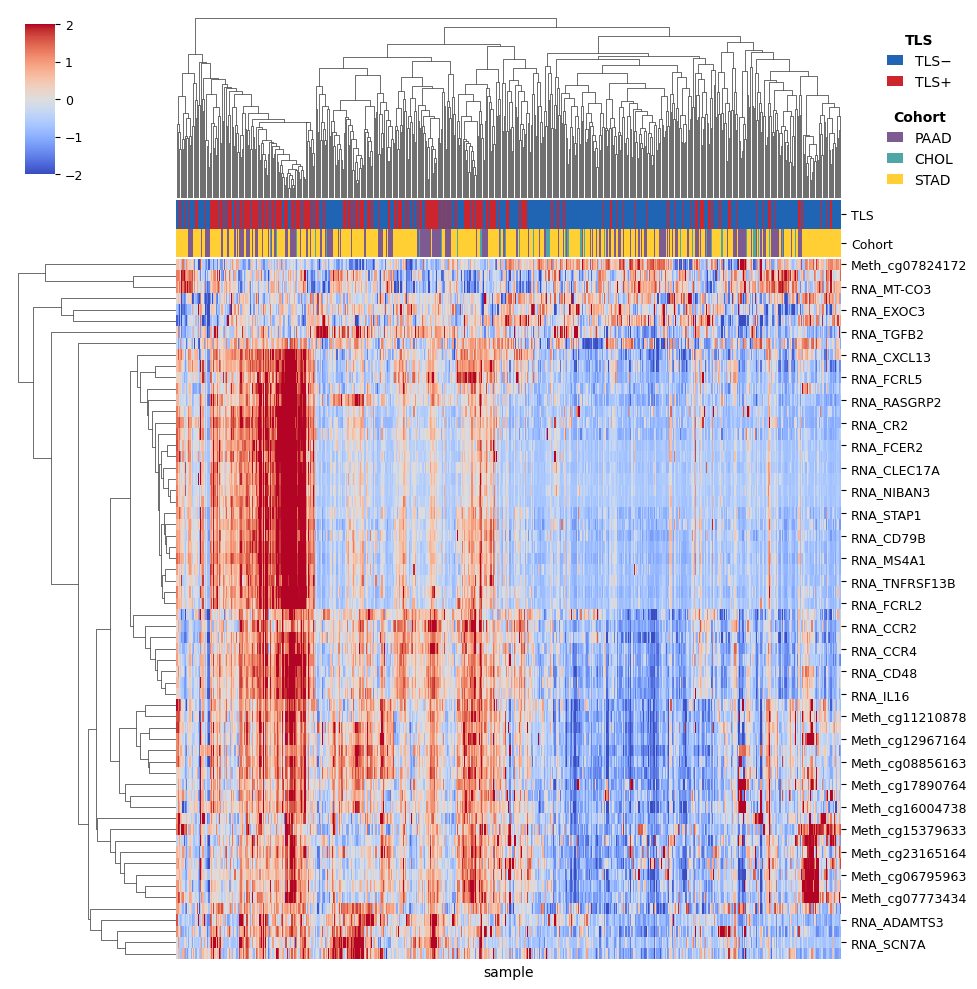

ALL (61, 4)
['Meth_cg07824172', 'RNA_MT-ND3', 'RNA_MT-CO3', 'RNA_GTF3C6', 'RNA_EXOC3', 'RNA_NOB1', 'RNA_TGFB2', 'Meth_cg15895782', 'RNA_CXCL13', 'RNA_CD79A', 'RNA_FCRL5', 'RNA_GPR18', 'RNA_RASGRP2', 'RNA_PAX5', 'RNA_CR2', 'RNA_CD22', 'RNA_FCER2', 'RNA_TCL1A', 'RNA_CLEC17A', 'RNA_CNR2', 'RNA_NIBAN3', 'RNA_FCRL1', 'RNA_STAP1', 'RNA_CD19', 'RNA_CD79B', 'RNA_FCRLA', 'RNA_MS4A1', 'RNA_BLK', 'RNA_TNFRSF13B', 'RNA_FCRL3', 'RNA_FCRL2', 'RNA_ETS1', 'RNA_CCR2', 'RNA_PIK3CD', 'RNA_CCR4', 'RNA_CCR7', 'RNA_CD48', 'RNA_IKZF1', 'RNA_IL16', 'Meth_cg02654291', 'Meth_cg11210878', 'Meth_cg27420224', 'Meth_cg12967164', 'Meth_cg02478828', 'Meth_cg08856163', 'Meth_cg22804839', 'Meth_cg17890764', 'Meth_cg13770399', 'Meth_cg16004738', 'Meth_cg12648201', 'Meth_cg15379633', 'Meth_cg03361776', 'Meth_cg23165164', 'Meth_cg14584255', 'Meth_cg06795963', 'Meth_cg06178315', 'Meth_cg07773434', 'Meth_cg07300384', 'RNA_ADAMTS3', 'RNA_ADRB2', 'RNA_SCN7A', 'RNA_DPT']


In [9]:
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from scipy.cluster.hierarchy import to_tree, leaves_list
import scipy.cluster.hierarchy as sch
import pandas as pd
import matplotlib.patches as mpatches

cohort_sample_sets = {
    "CHOL": set(chol_table.columns),
    "PAAD": set(paad_table.columns),
    "STAD": set(stad_table.columns),
}

for table_name, cluster_table in [("ALL", all_table_scaled)]:
    cluster_table_scaled = all_table_scaled

    # column annotation: TLS label + cohort
    sample_meta = cluster_table.sample_metadata.reindex(cluster_table_scaled.columns)
    tls_series = sample_meta["TLS"].astype(str).fillna("NA")

    if table_name == "ALL":
        cohort_series = pd.Series(index=cluster_table_scaled.columns, dtype="object")
        for s in cluster_table_scaled.columns:
            if s in cohort_sample_sets["CHOL"]:
                cohort_series.loc[s] = "CHOL"
            elif s in cohort_sample_sets["PAAD"]:
                cohort_series.loc[s] = "PAAD"
            elif s in cohort_sample_sets["STAD"]:
                cohort_series.loc[s] = "STAD"
            else:
                cohort_series.loc[s] = "Unknown"
    else:
        cohort_series = pd.Series(table_name, index=cluster_table_scaled.columns)

    tls_palette = {"0": "#2065B4", "1": "#CC252D"}
    cancer_palette = {"PAAD": "#7E5A92", "CHOL": "#4FA6A6", "STAD": "#ffcf33"}

    col_colors = pd.DataFrame(
        {
            "TLS": tls_series.map(tls_palette),
            "Cohort": cohort_series.map(lambda x: cancer_palette.get(x, "#7f7f7f")),
        },
        index=cluster_table_scaled.columns,
    )

    g = sns.clustermap(
        cluster_table_scaled,
        cmap="coolwarm",
        metric="correlation",
        col_cluster=True,
        row_cluster=True,
        col_colors=col_colors,
        cbar_pos=(0.03, 0.82, 0.03, 0.15),  # (left, bottom, width, height)
        vmin=-2,
        vmax=2,
        xticklabels=False
    )

    g.tick_params(axis='y', labelsize=9)

    # 用 Patch 製作兩個分開的 legend
    from matplotlib.patches import Patch
    tls_handles = [
        Patch(facecolor="#2065B4", edgecolor="none", label="TLS−"),
        Patch(facecolor="#CC252D", edgecolor="none", label="TLS+")
    ]
    cohort_handles = [
        Patch(facecolor="#7E5A92", edgecolor="none", label="PAAD"),
        Patch(facecolor="#4FA6A6", edgecolor="none", label="CHOL"),
        Patch(facecolor="#ffcf33", edgecolor="none", label="STAD")
    ]

    legend1 = g.ax_heatmap.legend(
    handles=tls_handles,
    title="TLS",
    loc="upper left",
    bbox_to_anchor=(1.05, 1.34),
    frameon=False,
    handlelength=1.2,
    ncol=1
    )
    legend1.get_title().set_fontsize(10)
    legend1.get_title().set_fontweight("bold")

    legend2 = g.ax_heatmap.legend(
        handles=cohort_handles,
        title="Cohort",
        loc="upper left",
        bbox_to_anchor=(1.05, 1.23),   # 向下移動到 y=0.85
        frameon=False,
        handlelength=1.2,
        ncol=1
    )
    legend2.get_title().set_fontsize(10)
    legend2.get_title().set_fontweight("bold")

    # 把第一個 legend 加回去（第二個會覆蓋，需要重新添加）
    g.ax_heatmap.add_artist(legend1)
    #plt.savefig("./tiff_figure/paper/covariation_clustermap.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
    plt.show()

    # row 的 linkage matrix
    row_linkage = g.dendrogram_row.linkage
    #sch.fcluster(row_linkage, t=7, criterion="maxclust")
    print(table_name, row_linkage.shape)

    # row 排序後的 index 位置和樣本名稱
    row_order_idx = g.dendrogram_row.reordered_ind
    row_order_labels = cluster_table_scaled.index[row_order_idx]
    print(row_order_labels.tolist())

In [10]:
import pandas as pd
import scipy.cluster.hierarchy as sch

# 取得每個 gene 的 cluster id
cluster_id = sch.fcluster(row_linkage, t=25, criterion="maxclust")

# gene 名稱順序要和建 linkage 的矩陣順序一致
gene_names = cluster_table_scaled.index

# 組成對照表
gene_cluster_df = pd.DataFrame({
    "gene": gene_names,
    "cluster": cluster_id
})

# 看每個 cluster 裡有哪些 gene
cluster_to_genes = gene_cluster_df.groupby("cluster")["gene"].apply(list)
print(cluster_to_genes)

cluster
1                                          [RNA_MT-ND3]
2                                          [RNA_MT-CO3]
3                                     [Meth_cg07824172]
4                                           [RNA_EXOC3]
5                                            [RNA_NOB1]
6                                          [RNA_GTF3C6]
7     [RNA_CXCL13, RNA_CD79A, RNA_FCRLA, RNA_MS4A1, ...
8     [RNA_ETS1, RNA_CCR7, RNA_CCR2, RNA_CCR4, RNA_I...
9     [Meth_cg02654291, Meth_cg27420224, Meth_cg0247...
10                                    [Meth_cg13770399]
11                                    [Meth_cg16004738]
12                                    [Meth_cg17890764]
13    [Meth_cg06795963, Meth_cg06178315, Meth_cg0777...
14                                    [Meth_cg14584255]
15                                    [Meth_cg23165164]
16                                    [Meth_cg03361776]
17                                    [Meth_cg15379633]
18                                    [M

In [11]:
gene_cluster_df[gene_cluster_df["cluster"] == 7]

,gene,cluster
1,RNA_CXCL13,7
4,RNA_CD79A,7
5,RNA_FCRLA,7
8,RNA_MS4A1,7
10,RNA_CR2,7
12,RNA_CD79B,7
16,RNA_BLK,7
18,RNA_FCRL3,7
26,RNA_FCRL2,7
31,RNA_CD22,7


CHOL (22, 4)
['RNA_CD22', 'RNA_CXCL13', 'RNA_CD79A', 'RNA_FCRL5', 'RNA_CD79B', 'RNA_GPR18', 'RNA_RASGRP2', 'RNA_CR2', 'RNA_CLEC17A', 'RNA_FCRL3', 'RNA_FCRLA', 'RNA_TCL1A', 'RNA_NIBAN3', 'RNA_STAP1', 'RNA_MS4A1', 'RNA_FCRL2', 'RNA_CD19', 'RNA_TNFRSF13B', 'RNA_BLK', 'RNA_CNR2', 'RNA_PAX5', 'RNA_FCER2', 'RNA_FCRL1']
PAAD (22, 4)
['RNA_CD79A', 'RNA_FCRL5', 'RNA_RASGRP2', 'RNA_GPR18', 'RNA_FCRL3', 'RNA_FCRL2', 'RNA_TNFRSF13B', 'RNA_PAX5', 'RNA_CD22', 'RNA_STAP1', 'RNA_CD79B', 'RNA_FCER2', 'RNA_TCL1A', 'RNA_CLEC17A', 'RNA_FCRLA', 'RNA_MS4A1', 'RNA_CD19', 'RNA_NIBAN3', 'RNA_FCRL1', 'RNA_BLK', 'RNA_CNR2', 'RNA_CXCL13', 'RNA_CR2']
STAD (22, 4)
['RNA_CXCL13', 'RNA_CD79A', 'RNA_FCRL5', 'RNA_GPR18', 'RNA_PAX5', 'RNA_RASGRP2', 'RNA_CR2', 'RNA_FCER2', 'RNA_TCL1A', 'RNA_CD19', 'RNA_CLEC17A', 'RNA_STAP1', 'RNA_FCRLA', 'RNA_CD79B', 'RNA_MS4A1', 'RNA_CD22', 'RNA_BLK', 'RNA_TNFRSF13B', 'RNA_CNR2', 'RNA_NIBAN3', 'RNA_FCRL1', 'RNA_FCRL3', 'RNA_FCRL2']


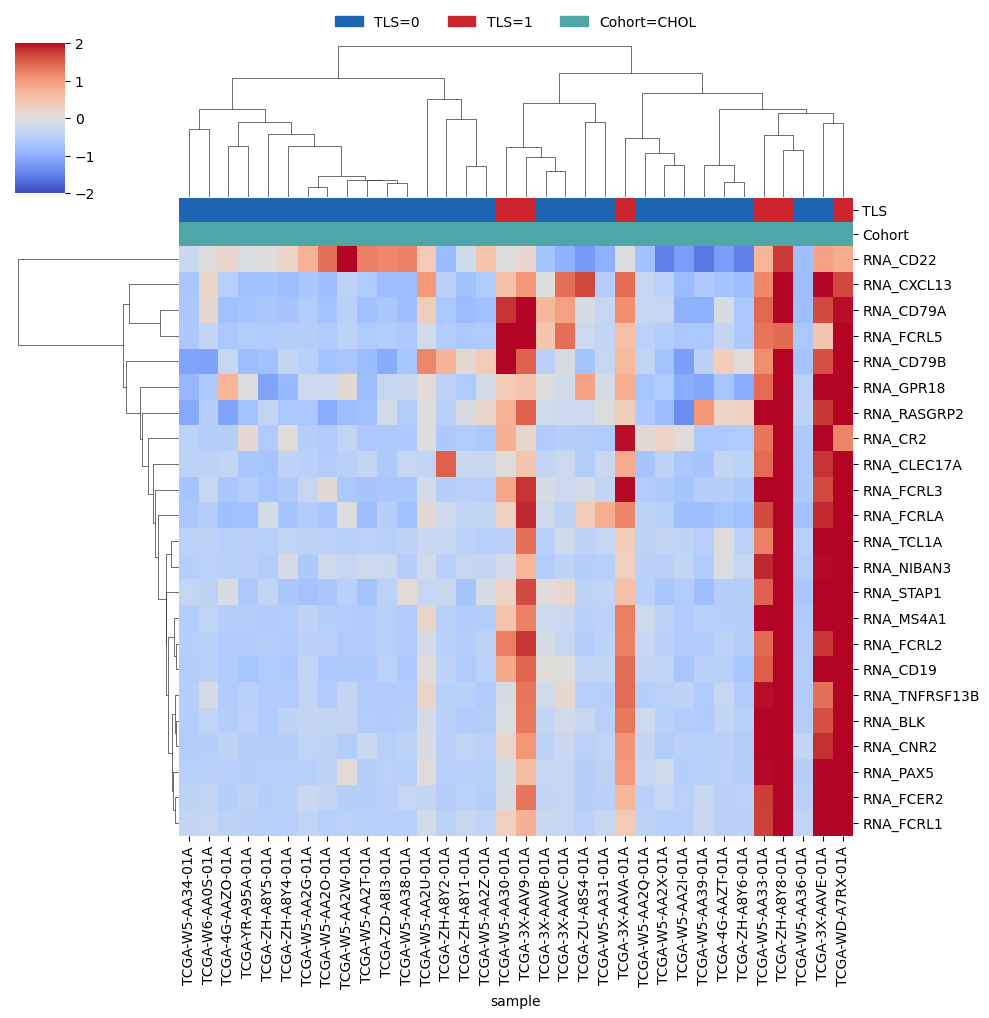

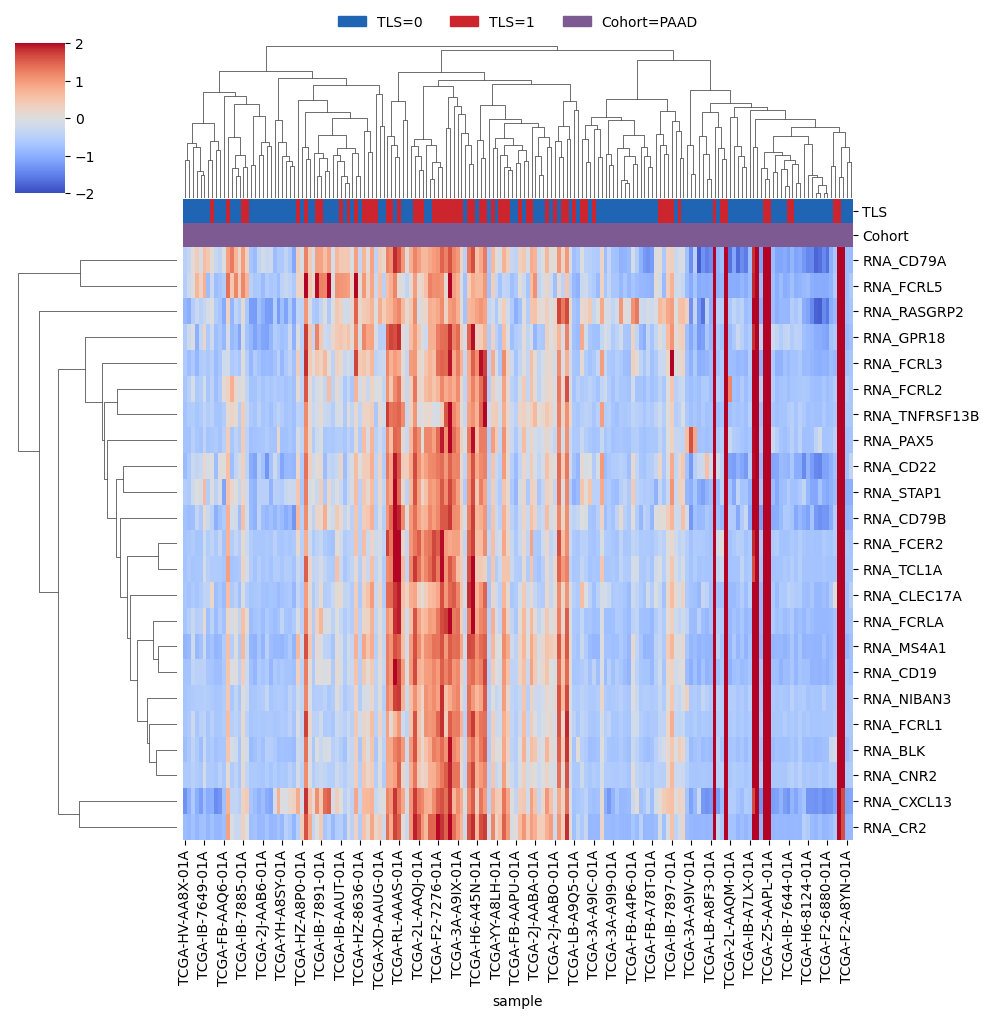

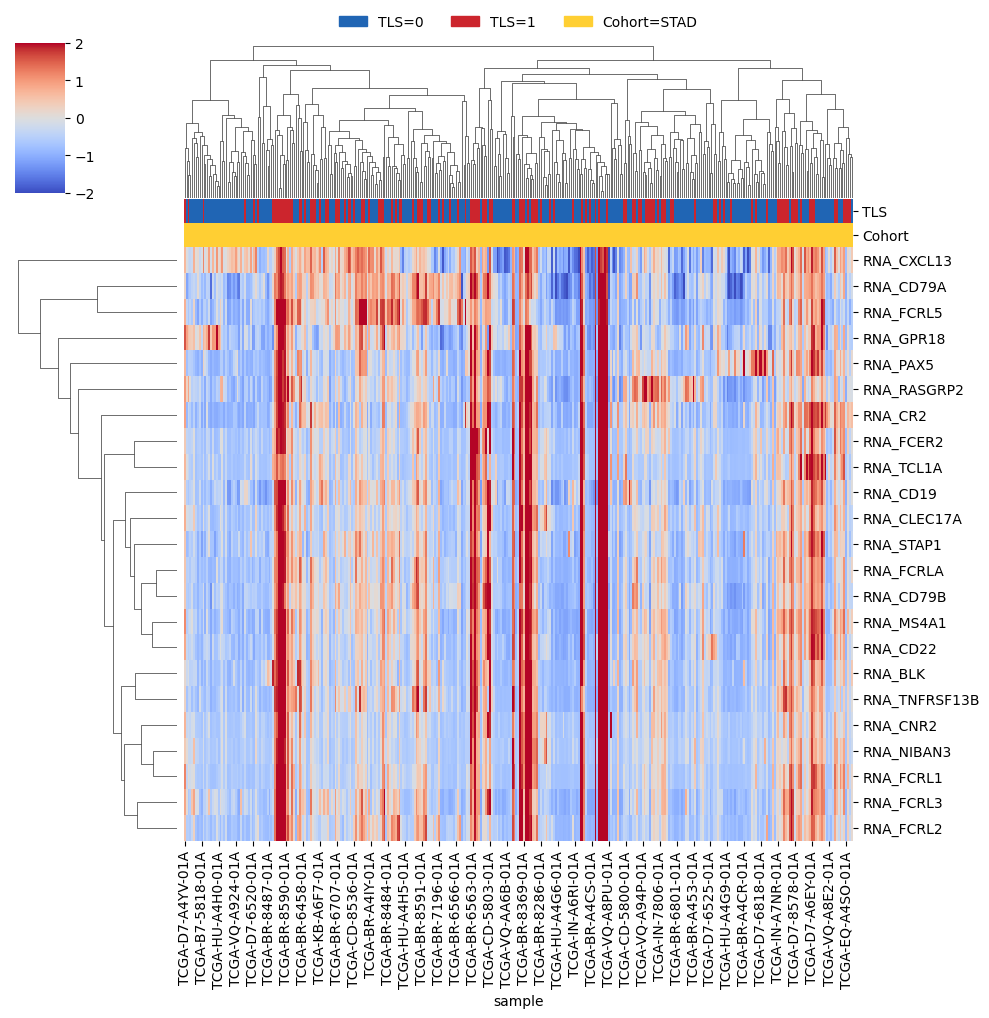

In [13]:
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from scipy.cluster.hierarchy import to_tree, leaves_list
import scipy.cluster.hierarchy as sch
import pandas as pd
import matplotlib.patches as mpatches

gene7 = gene_cluster_df[gene_cluster_df["cluster"] == 7]["gene"].tolist()

cohort_sample_sets = {
    "CHOL": set(chol_table.columns),
    "PAAD": set(paad_table.columns),
    "STAD": set(stad_table.columns),
}

for table_name, cluster_table in [("CHOL", chol_table_scaled), ("PAAD", paad_table_scaled), ("STAD", stad_table_scaled)]:
    subset_cluster_table = cluster_table.subset(features=gene7)

    # 對 training validation dataset 進行 z-score normalization
    scaler = StandardScaler()
    cluster_table_scaled = pd.DataFrame(
        scaler.fit_transform(subset_cluster_table.T).T,
        index=subset_cluster_table.index,
        columns=subset_cluster_table.columns,
    )

    # column annotation: TLS label + cohort
    sample_meta = subset_cluster_table.sample_metadata.reindex(cluster_table_scaled.columns)
    tls_series = sample_meta["TLS"].astype(str).fillna("NA")

    if table_name == "ALL":
        cohort_series = pd.Series(index=cluster_table_scaled.columns, dtype="object")
        for s in cluster_table_scaled.columns:
            if s in cohort_sample_sets["CHOL"]:
                cohort_series.loc[s] = "CHOL"
            elif s in cohort_sample_sets["PAAD"]:
                cohort_series.loc[s] = "PAAD"
            elif s in cohort_sample_sets["STAD"]:
                cohort_series.loc[s] = "STAD"
            else:
                cohort_series.loc[s] = "Unknown"
    else:
        cohort_series = pd.Series(table_name, index=cluster_table_scaled.columns)


    tls_palette = {"0": "#2065B4", "1": "#CC252D"}
    cancer_palette = {"PAAD": "#7E5A92", "CHOL": "#4FA6A6", "STAD": "#ffcf33"}

    col_colors = pd.DataFrame(
        {
            "TLS": tls_series.map(tls_palette),
            "Cohort": cohort_series.map(lambda x: cancer_palette.get(x, "#7f7f7f")),
        },
        index=cluster_table_scaled.columns,
    )

    g = sns.clustermap(
        cluster_table_scaled,
        cmap="coolwarm",
        metric="correlation",
        cbar_pos=(0.02, 0.83, 0.05, 0.15),
        vmin=-2,
        vmax=2,
        col_colors=col_colors,
    )

    # 加上 annotation legend
    tls_handles = [mpatches.Patch(color=c, label=f"TLS={k}") for k, c in tls_palette.items()]
    cohort_handles = [
        mpatches.Patch(color=cancer_palette[k], label=f"Cohort={k}")
        for k in ["CHOL", "PAAD", "STAD", "Unknown"]
        if (cohort_series == k).any()
    ]
    g.ax_col_dendrogram.legend(
        handles=tls_handles + cohort_handles,
        loc="center",
        bbox_to_anchor=(0.5, 1.1),
        ncol=5,
        frameon=False,
    )

    # row 的 linkage matrix
    row_linkage = g.dendrogram_row.linkage
    #sch.fcluster(row_linkage, t=7, criterion="maxclust")
    print(table_name, row_linkage.shape)

    # row 排序後的 index 位置和樣本名稱
    row_order_idx = g.dendrogram_row.reordered_ind
    row_order_labels = cluster_table_scaled.index[row_order_idx]
    print(row_order_labels.tolist())

### Correlation in Cluster 7

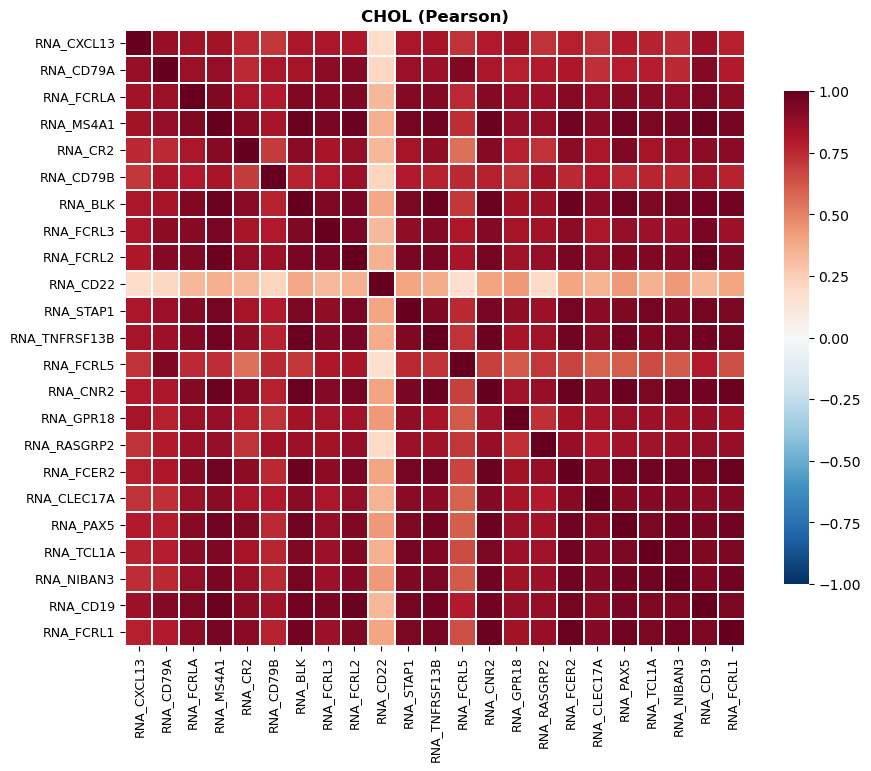

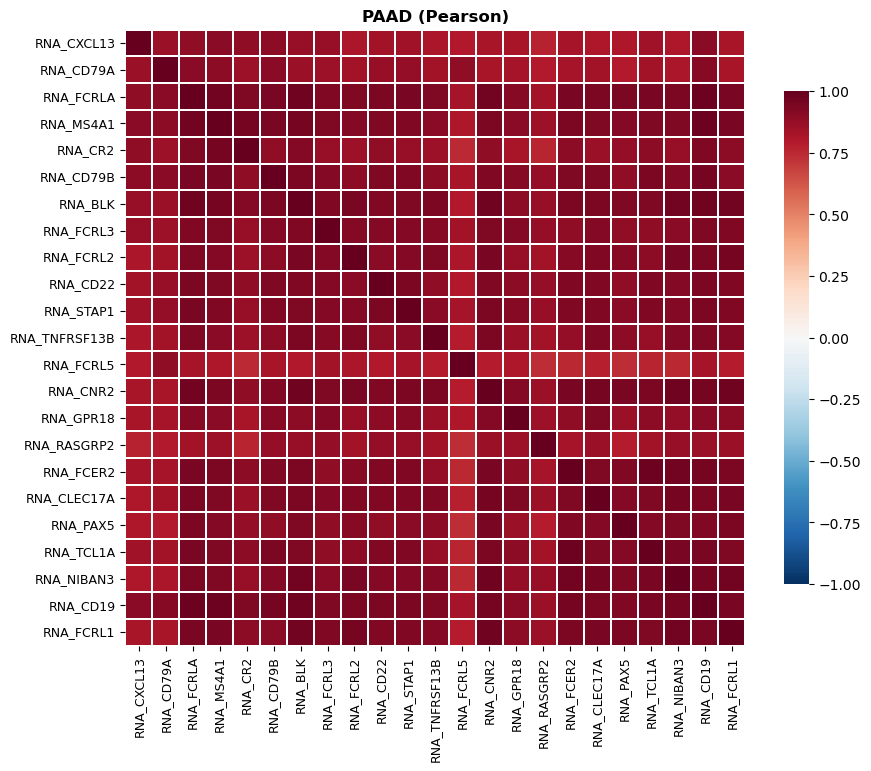

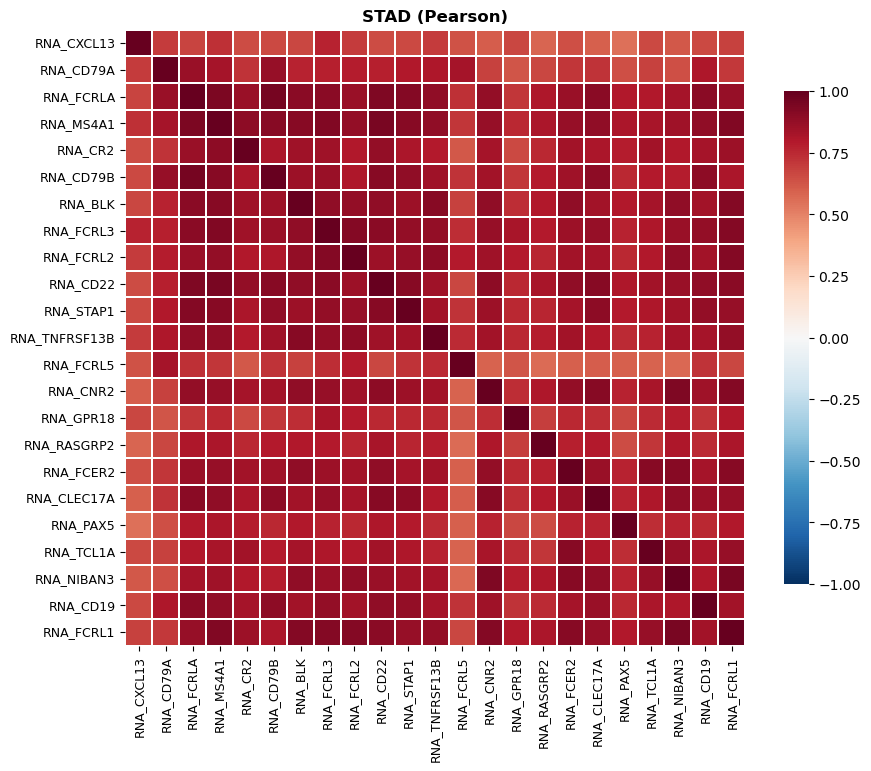

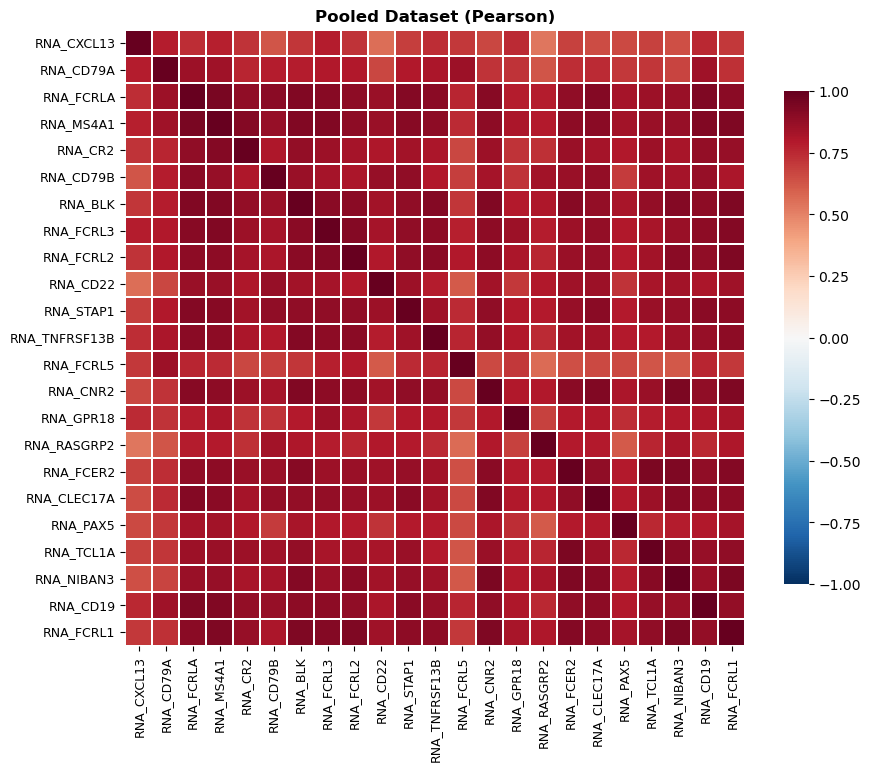

In [14]:
# Co-variation of gene cluster 7
gene7 = gene_cluster_df[gene_cluster_df["cluster"] == 7]["gene"].tolist()

chol_combined = extract_features(chol_rna_df, chol_meth_df, gene7)
corr_in_chol = chol_combined.corr(method="pearson")

# 同理用 PAAD samples
paad_combined = extract_features(paad_rna_df, paad_meth_df, gene7)
corr_in_paad = paad_combined.corr(method="pearson")

# 同理用 STAD samples
stad_combined = extract_features(stad_rna_df, stad_meth_df, gene7)
corr_in_stad = stad_combined.corr(method="pearson")

# 同理用 ALL samples
all_combined = extract_features(all_rna_df, all_meth_df, gene7)
corr_in_all = all_combined.corr(method="pearson")

# Plot
fig = plt.figure(figsize=(10, 8))
ax1 = sns.heatmap(corr_in_chol, cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.8})
ax1.set_title("CHOL (Pearson)", fontweight="bold")
ax1.tick_params(labelsize=9)
plt.setp(ax1.get_xticklabels(), rotation=90, ha="center")
#plt.savefig("./tiff_figure/paper/covariation_corr_CHOL.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

fig = plt.figure(figsize=(10, 8))
ax1 = sns.heatmap(corr_in_paad, cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.8})
ax1.set_title("PAAD (Pearson)", fontweight="bold")
ax1.tick_params(labelsize=9)
plt.setp(ax1.get_xticklabels(), rotation=90, ha="center")
#plt.savefig("./tiff_figure/paper/covariation_corr_PAAD.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

fig = plt.figure(figsize=(10, 8))
ax1 = sns.heatmap(corr_in_stad, cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.8})
ax1.set_title("STAD (Pearson)", fontweight="bold")
ax1.tick_params(labelsize=9)
plt.setp(ax1.get_xticklabels(), rotation=90, ha="center")
#plt.savefig("./tiff_figure/paper/covariation_corr_STAD.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

fig = plt.figure(figsize=(10, 8))
ax1 = sns.heatmap(corr_in_all, cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.8})
ax1.set_title("Pooled Dataset (Pearson)", fontweight="bold")
ax1.tick_params(labelsize=9)
plt.setp(ax1.get_xticklabels(), rotation=90, ha="center")
#plt.savefig("./tiff_figure/paper/covariation_corr_pooled.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

PAAD-specific : CD79B、GPR18

CHOL-specific : CD79A、RASGRP2、FCRL3、FCRL5

STAD-specific : NIBAN3、TNFRSF13B

In [69]:
set(top_features_STAD) - set(top_features_PAAD) - set(top_features_CHOL)

{'Meth_cg07824172',
 'Meth_cg18634760',
 'Meth_cg24083364',
 'RNA_CCR7',
 'RNA_NIBAN3',
 'RNA_TNFRSF13B'}

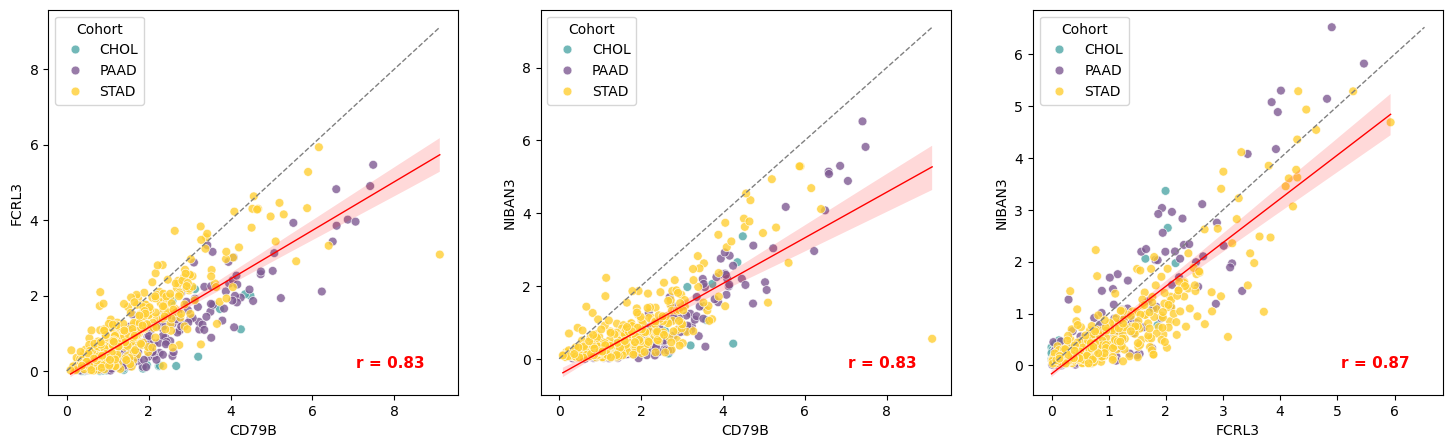

In [68]:
# Scatter plots for gene pairs (use all_rna_df) — color by cohort, draw regression line, show Pearson r
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

def _get_gene_series_from_all(rna_df, gene_name):
    # all_rna_df expected: rows = samples, cols = genes OR rows genes, cols samples
    if hasattr(rna_df, "to_pandas"):
        try:
            df = rna_df.to_pandas()
        except Exception:
            df = pd.DataFrame(rna_df)
    else:
        df = pd.DataFrame(rna_df)

    # if genes are columns (samples x genes)
    if gene_name in df.columns or f"RNA_{gene_name}" in df.columns:
        key = gene_name if gene_name in df.columns else f"RNA_{gene_name}"
        return pd.to_numeric(df[key], errors="coerce")

    # if genes are index (genes x samples)
    if gene_name in df.index or f"RNA_{gene_name}" in df.index:
        key = gene_name if gene_name in df.index else f"RNA_{gene_name}"
        return pd.to_numeric(df.loc[key], errors="coerce")

    raise KeyError(f"Gene {gene_name} not found in all_rna_df")


# cohort detection: check which cohort set contains sample name
cohort_palette = {"PAAD": "#7E5A92", "CHOL": "#4FA6A6", "STAD": "#ffcf33"}


def sample_to_cohort(sample_name, cohort_sample_sets):
    for k, sset in cohort_sample_sets.items():
        if sample_name in sset:
            return k
    return "Unknown"

pairs = [("CD79B", "FCRL3"), ("CD79B", "NIBAN3"), ("FCRL3", "NIBAN3")]
g1, g2 = pairs[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (g1, g2) in zip(axes, pairs):
    x = _get_gene_series_from_all(all_rna_df, g1)
    y = _get_gene_series_from_all(all_rna_df, g2)

    # ensure index alignment
    df_plot = pd.DataFrame({g1: x, g2: y}).dropna()
    cohorts = [sample_to_cohort(s, cohort_sample_sets) for s in df_plot.index]
    df_plot["cohort"] = cohorts

    # scatter colored by cohort
    sns.scatterplot(data=df_plot, x=g1, y=g2, hue="cohort", palette=cohort_palette, s=40, alpha=0.8, ax=ax)

    # regression line (all data)
    sns.regplot(data=df_plot, x=g1, y=g2, scatter=False, ax=ax, color="red", line_kws={"linewidth": 1, "linestyle": "-"})

    # y=x reference line
    xy_min = min(df_plot[g1].min(), df_plot[g2].min())
    xy_max = max(df_plot[g1].max(), df_plot[g2].max())
    ax.plot([xy_min, xy_max], [xy_min, xy_max], color="grey", linestyle="--", linewidth=1)

    # Pearson r
    if len(df_plot) >= 2:
        r, p = pearsonr(df_plot[g1], df_plot[g2])
        ax.text(0.75, 0.1, f"r = {r:.2f}", transform=ax.transAxes, verticalalignment='top', color="red", fontsize=11, fontweight="bold")
        #ax.set_title(f"{g1} vs. {g2} (r={r:.2f})", fontweight="bold")

    ax.set_xlabel(g1)
    ax.set_ylabel(g2)
    ax.legend(title="Cohort")
    
#plt.tight_layout()
plt.savefig(f"./tiff_figure/paper/covariation_scatterplot.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

### Correlation in union TLS signature sets
確認5種signatures set是不是內部特徵的correlation很高 

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Load features & tables 
top_features_CHOL = np.load(f"/home/data/data_YM313112004/TLS_model/results/CHOL/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_PAAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_STAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/STAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
pooled_sig = np.load("/home/data/data_YM313112004/TLS_model/results/all/selected_features/TLS_signatures_42.npy", allow_pickle=True)
consensus_sig = np.load("/home/data/data_YM313112004/TLS_model/results/all/selected_features/TLS_signatures_across_cancers_42.npy", allow_pickle=True)

chol_rna  = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite")
paad_rna  = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite")
stad_rna  = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite")
chol_meth = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite")
paad_meth = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite")
stad_meth = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite")
all_rna  = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/all/table/rna_table.sqlite")
all_meth = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/all/table/meth_table.sqlite")

chol_rna_df  = chol_rna.T   # (172 samples × 19026 genes)
paad_rna_df  = paad_rna.T    
stad_rna_df  = stad_rna.T
chol_meth_df = chol_meth.T
paad_meth_df = paad_meth.T
stad_meth_df = stad_meth.T
all_rna_df  = all_rna.T
all_meth_df = all_meth.T

print("CHOL RNA shape :", chol_rna_df.shape)
print("PAAD RNA shape :", paad_rna_df.shape)
print("STAD RNA shape :", stad_rna_df.shape)
print("CHOL Meth shape:", chol_meth_df.shape)
print("PAAD Meth shape:", paad_meth_df.shape)
print("STAD Meth shape:", stad_meth_df.shape)
print("All RNA shape :", all_rna_df.shape)
print("All Meth shape :", all_meth_df.shape)

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/all/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/all/table/meth_table.sqlite
CHOL RNA shape : (34, 19026)
PAAD RNA shape : (172, 19026)
STAD RNA shape : (355, 19026)
CHOL Meth shape: (34, 146132)
PAAD Meth shape: (172, 154359)
STAD Meth shape: (355, 156220)
All RNA shape : (561, 190

In [6]:
# 取 feature expression（保留 RNA_ / Meth_ 前綴）
def extract_features(rna_df, meth_df, top_features):
    selected = {}
    missing = []
    top_features = pd.Series(top_features).astype(str)

    for feat in top_features:
        if feat.startswith("RNA_"):
            key = feat.replace("RNA_", "", 1)
            src = rna_df
        elif feat.startswith("Meth_"):
            key = feat.replace("Meth_", "", 1)
            src = meth_df
        else:
            missing.append(feat)
            continue

        val = None
        if key in src.columns:
            val = src[key]
        elif key in src.index:
            val = src.loc[key]

        if val is None:
            missing.append(feat)
            continue

        if isinstance(val, pd.Series):
            ser = pd.to_numeric(val, errors="coerce")
        elif isinstance(val, pd.DataFrame):
            if val.shape[1] == 1:
                ser = pd.to_numeric(val.iloc[:, 0], errors="coerce")
            else:
                ser = val.apply(pd.to_numeric, errors="coerce").mean(axis=1)
        else:
            arr = np.asarray(val)
            if arr.ndim == 0:
                arr = np.array([arr.item()])
            elif arr.ndim > 1:
                arr = arr.reshape(arr.shape[0], -1)
                arr = np.nanmean(arr, axis=1)
            ser = pd.Series(pd.to_numeric(arr, errors="coerce"))

        selected[feat] = ser.reset_index(drop=True)

    if missing:
        print(f"WARNING missing features: {missing}")

    if not selected:
        return pd.DataFrame()

    max_len = max(len(s) for s in selected.values())
    selected = {k: v.reindex(range(max_len)) for k, v in selected.items()}
    return pd.concat(selected, axis=1)

chol_expr = extract_features(chol_rna_df, chol_meth_df, top_features_CHOL)
paad_expr = extract_features(paad_rna_df, paad_meth_df, top_features_PAAD)
stad_expr = extract_features(stad_rna_df, stad_meth_df, top_features_STAD)
print("CHOL expr shape:", chol_expr.shape)  
print("PAAD expr shape:", paad_expr.shape)
print("STAD expr shape:", stad_expr.shape)

CHOL expr shape: (34, 38)
PAAD expr shape: (172, 24)
STAD expr shape: (355, 16)


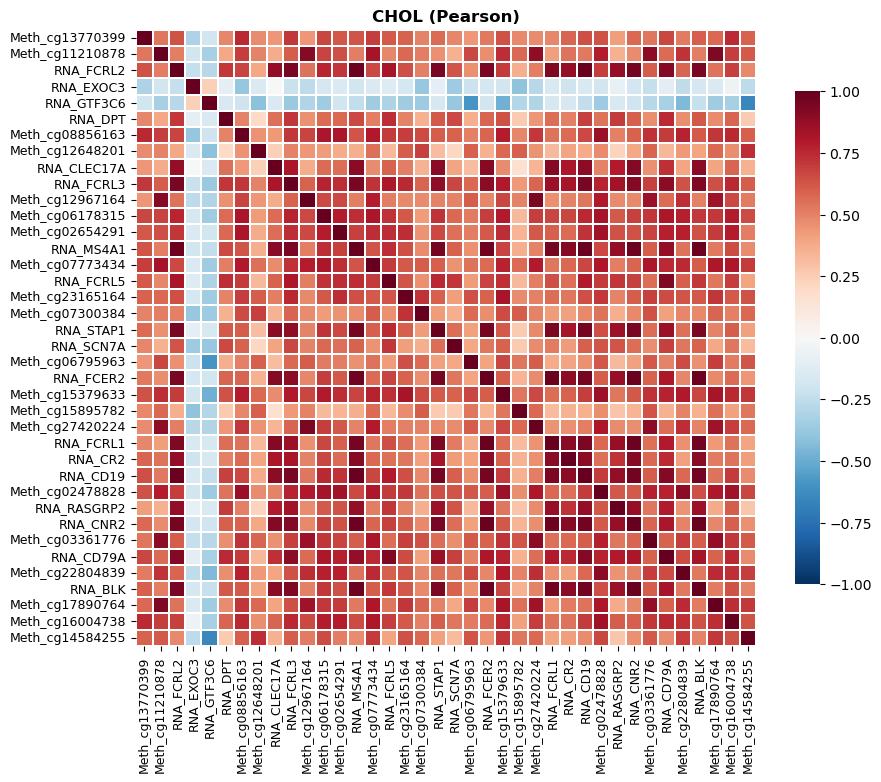

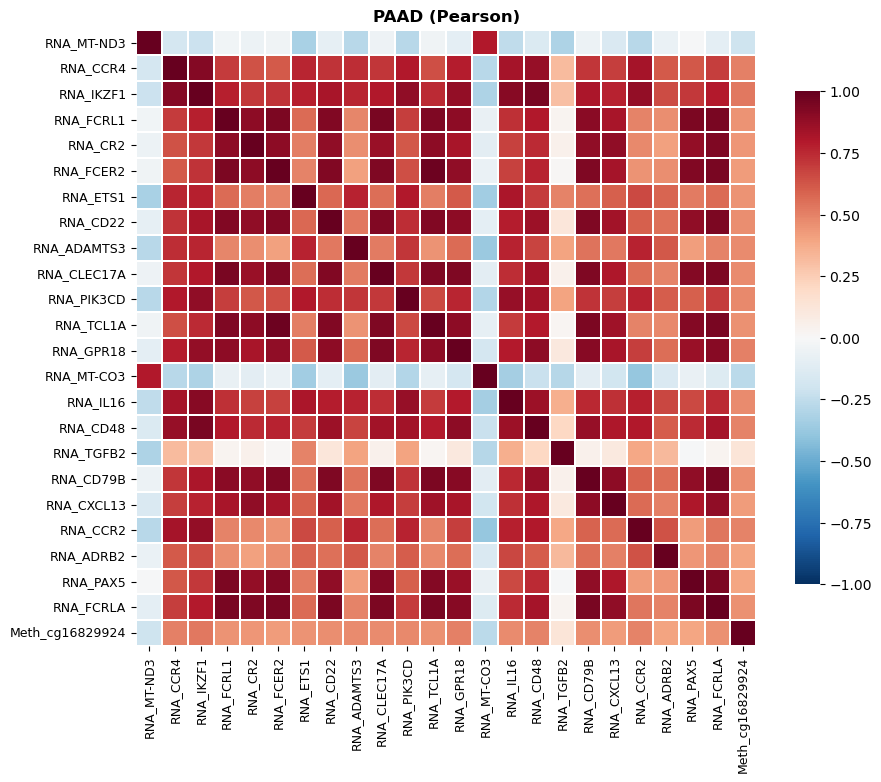

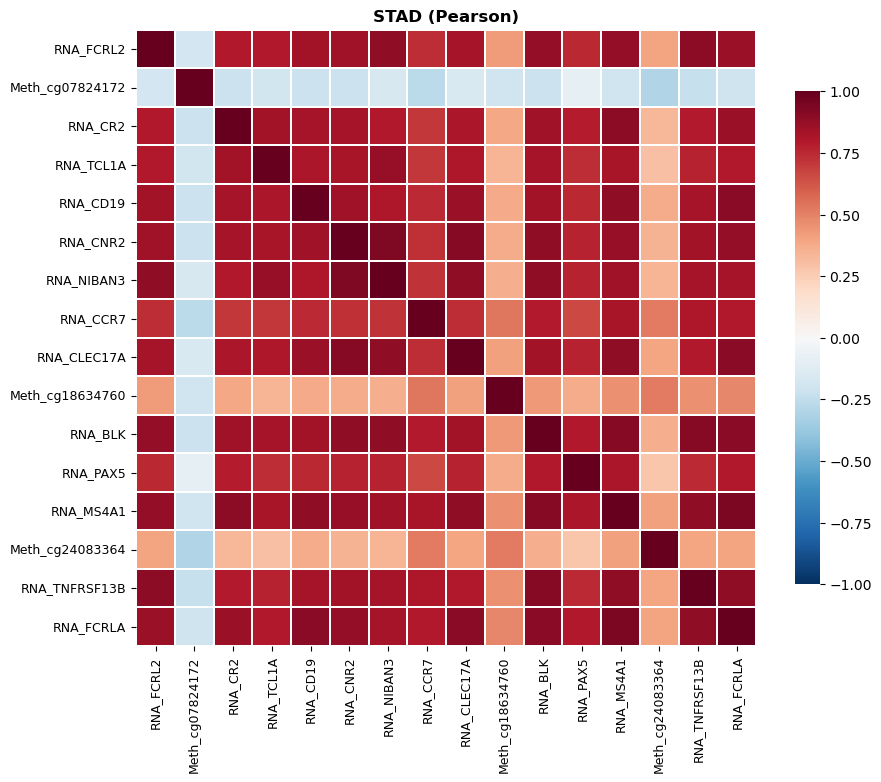

In [ ]:
# Correlation in cancer-specific signature sets
corr_in_chol = chol_expr.corr(method="pearson")
corr_in_paad = paad_expr.corr(method="pearson")
corr_in_stad = stad_expr.corr(method="pearson")

fig = plt.figure(figsize=(10, 8))
ax1 = sns.heatmap(corr_in_chol, cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.8})
ax1.set_title("CHOL (Pearson)", fontweight="bold")
ax1.tick_params(labelsize=9)
plt.setp(ax1.get_xticklabels(), rotation=90, ha="center")
plt.show()

fig = plt.figure(figsize=(10, 8))
ax1 = sns.heatmap(corr_in_paad, cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.8})
ax1.set_title("PAAD (Pearson)", fontweight="bold")
ax1.tick_params(labelsize=9)
plt.setp(ax1.get_xticklabels(), rotation=90, ha="center")
plt.show()

fig = plt.figure(figsize=(10, 8))
ax1 = sns.heatmap(corr_in_stad, cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.8})
ax1.set_title("STAD (Pearson)", fontweight="bold")
ax1.tick_params(labelsize=9)
plt.setp(ax1.get_xticklabels(), rotation=90, ha="center")
plt.show()

WARNING missing features: ['Meth_cg16829924']
WARNING missing features: ['Meth_cg18634760', 'Meth_cg24083364']


,signature_set,cancer,n_features,mean_corr,mean_abs_corr,median_abs_corr,max_abs_corr
0,CHOL-specific,CHOL,38,0.530864,0.582134,0.584763,0.990646
1,CHOL-specific,PAAD,38,0.512938,0.515326,0.520357,0.978722
2,CHOL-specific,STAD,38,0.434551,0.448430,0.453375,0.925978
9,Consensus,CHOL,12,0.933664,0.933664,0.936590,0.990646
10,Consensus,PAAD,12,0.937143,0.937143,0.941210,0.978722
11,Consensus,STAD,12,0.849532,0.849532,0.849573,0.942645
3,PAAD-specific,CHOL,23,0.485946,0.512651,0.535027,0.985614
4,PAAD-specific,PAAD,24,0.531882,0.588051,0.636868,0.978206
5,PAAD-specific,STAD,24,0.441760,0.483255,0.529032,0.954450
12,Pooled,CHOL,13,0.797531,0.797531,0.911941,0.988355


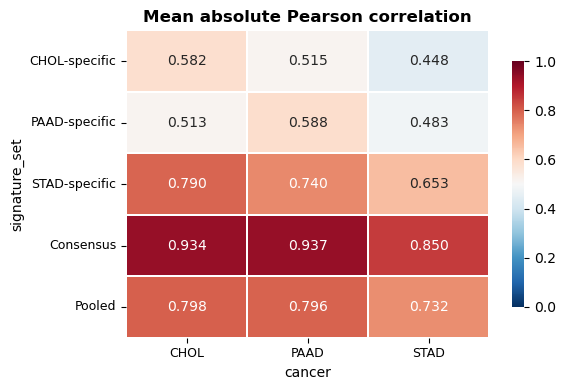

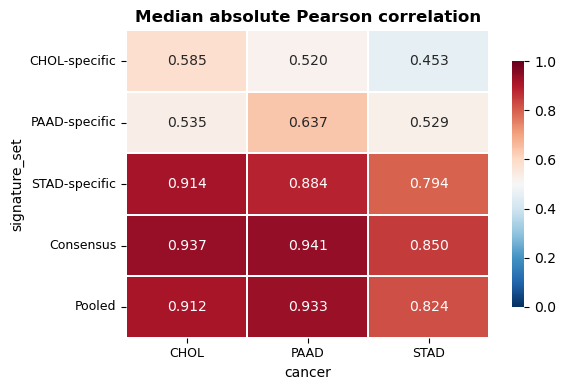

In [ ]:
# Cross-cancer correlation summary for five signature sets
signature_sets = {
    "CHOL-specific": top_features_CHOL,
    "PAAD-specific": top_features_PAAD,
    "STAD-specific": top_features_STAD,
    "Consensus": consensus_sig,
    "Pooled": pooled_sig,
}

cancer_exprs = {
    "CHOL": (chol_rna_df, chol_meth_df),
    "PAAD": (paad_rna_df, paad_meth_df),
    "STAD": (stad_rna_df, stad_meth_df),
}


def summarize_corr(expr_df):
    corr = expr_df.corr(method="pearson")
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack() # 取上三角矩陣就好 (k=1 不要對角線)
    return {
        "n_features": expr_df.shape[1],
        "mean_corr": upper.mean(),
        "mean_abs_corr": upper.abs().mean(),
        "median_abs_corr": upper.abs().median(),
        "max_abs_corr": upper.abs().max(),
    }, corr


summary_rows = []
corr_mats = {}

for sig_name, sig in signature_sets.items():
    for cancer_name, (rna_df, meth_df) in cancer_exprs.items():
        expr = extract_features(rna_df, meth_df, sig)
        stats, corr = summarize_corr(expr)
        summary_rows.append({"signature_set": sig_name, "cancer": cancer_name, **stats})
        corr_mats[(sig_name, cancer_name)] = corr

summary_df = pd.DataFrame(summary_rows)
display(summary_df.sort_values(["signature_set", "cancer"]))

# mean absolute correlation heatmap
summary_pivot = summary_df.pivot(index="signature_set", columns="cancer", values="mean_abs_corr")
summary_pivot = summary_pivot.reindex(signature_sets.keys())

plt.figure(figsize=(6, 4))
ax = sns.heatmap(
    summary_pivot,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=0,
    vmax=1,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8},
)
ax.set_title("Mean absolute Pearson correlation", fontweight="bold")
ax.tick_params(labelsize=9)
plt.tight_layout()
plt.show()


# median absolute correlation heatmap
summary_pivot = summary_df.pivot(index="signature_set", columns="cancer", values="median_abs_corr")
summary_pivot = summary_pivot.reindex(signature_sets.keys())

plt.figure(figsize=(6, 4))
ax = sns.heatmap(
    summary_pivot,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=0,
    vmax=1,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8},
)
ax.set_title("Median absolute Pearson correlation", fontweight="bold")
ax.tick_params(labelsize=9)
plt.tight_layout()
plt.show()

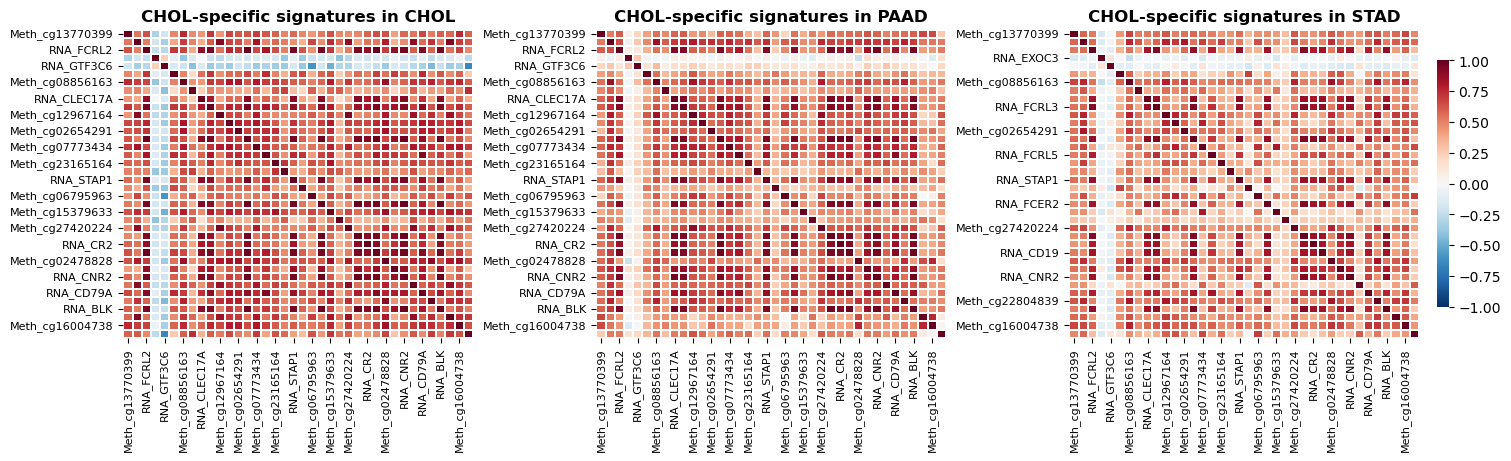

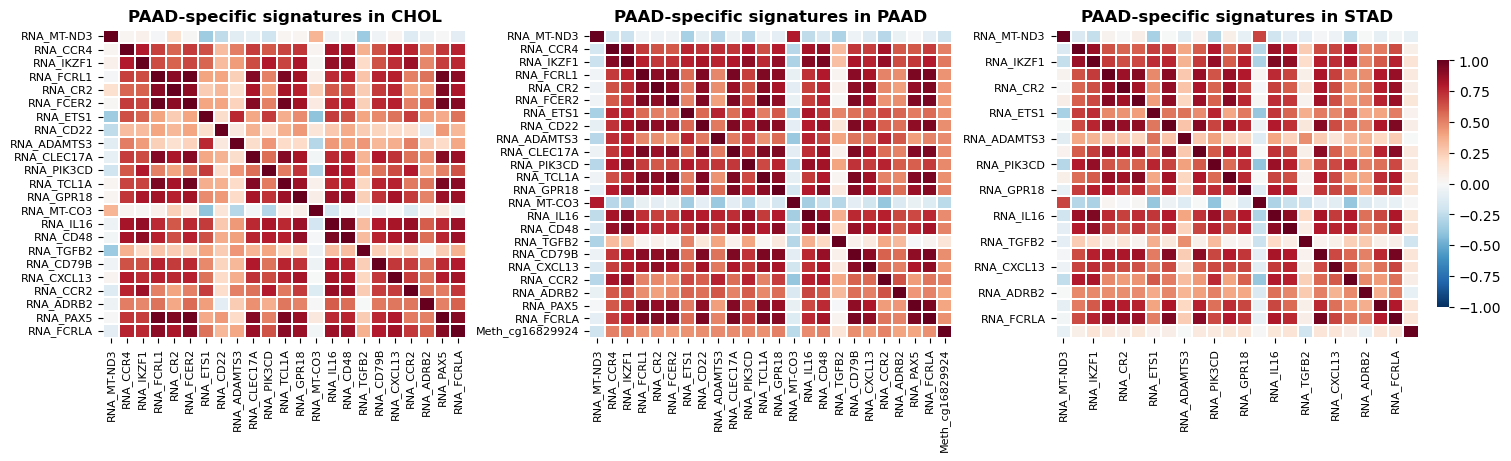

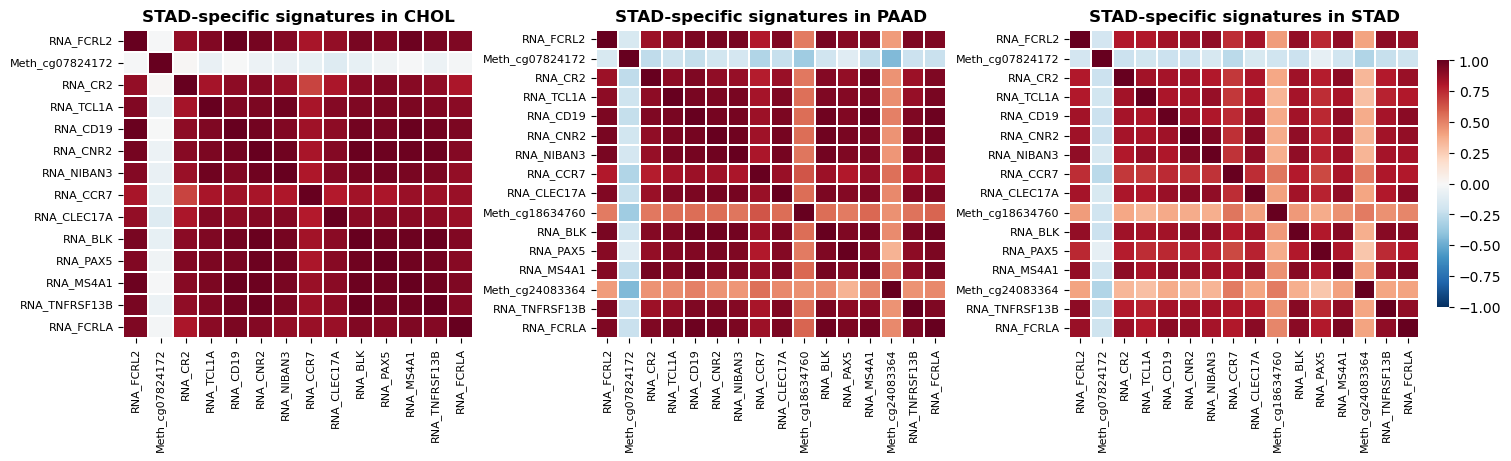

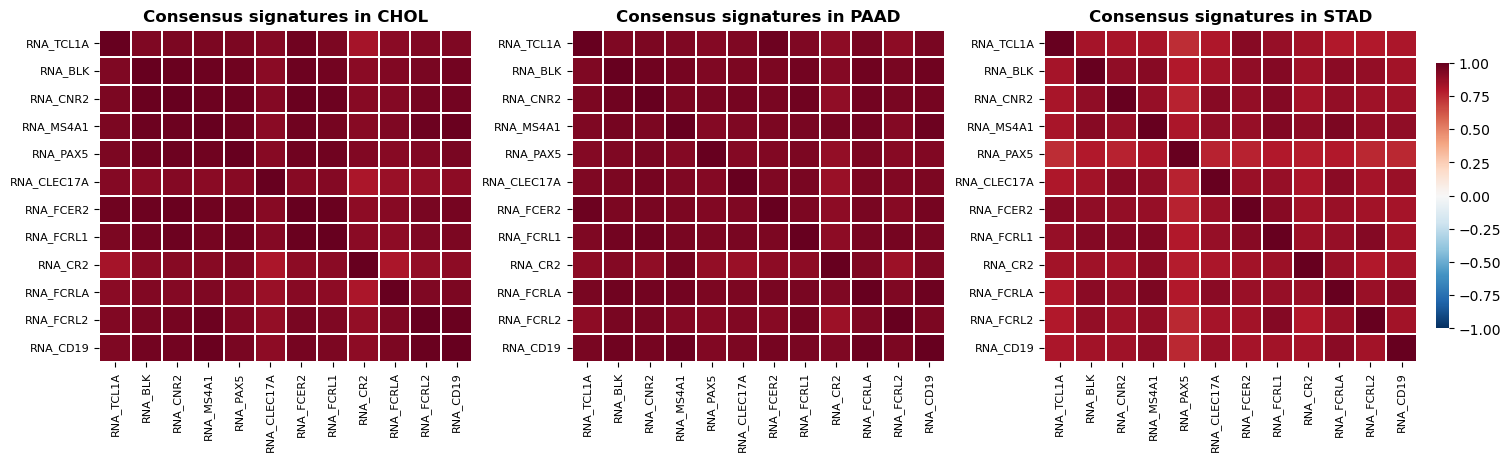

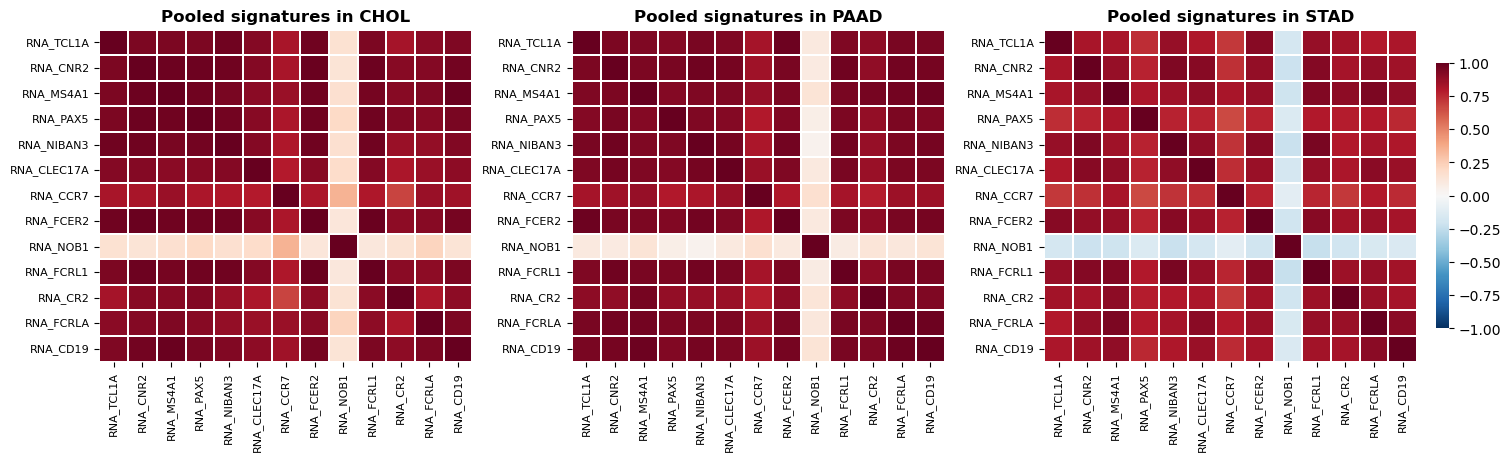

In [23]:
def plot_cross_cancer_corr(sig_name):
    fig, axes = plt.subplots(1, len(cancer_exprs), figsize=(5 * len(cancer_exprs), 4.5), constrained_layout=True)
    if len(cancer_exprs) == 1:
        axes = [axes]
    cancer_names = list(cancer_exprs.keys())
    for ax, cancer_name in zip(axes, cancer_names):
        corr = corr_mats[(sig_name, cancer_name)]
        sns.heatmap(
            corr,
            cmap="RdBu_r",
            vmin=-1,
            vmax=1,
            linewidths=0.3,
            cbar=(cancer_name == cancer_names[-1]),
            cbar_kws={"shrink": 0.8},
            ax=ax,
        )
        ax.set_title(f"{sig_name} signatures in {cancer_name}", fontweight="bold")
        ax.tick_params(labelsize=8)
        plt.setp(ax.get_xticklabels(), rotation=90, ha="center")
        plt.setp(ax.get_yticklabels(), rotation=0)
    plt.show()

plot_cross_cancer_corr("CHOL-specific")
plot_cross_cancer_corr("PAAD-specific")
plot_cross_cancer_corr("STAD-specific")
plot_cross_cancer_corr("Consensus")
plot_cross_cancer_corr("Pooled")